# Practical Work 5 — Imbalanced Classification

**Project:** MACHINEGUARD  
**Level:** C

## Objective

To develop a binary classification model for predicting machine failures, compare methods for handling class imbalance, and evaluate classification performance using appropriate metrics and decision thresholds.

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    precision_recall_curve
)
from sklearn.utils import resample

print("MACHINEGUARD PR5")
print("All libraries imported successfully!")


MACHINEGUARD PR5
All libraries imported successfully!


In [2]:

project_dir = Path.cwd().resolve()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

df = pd.read_csv(
    project_dir / "data" / "raw" / "ai4i2020.csv"
)

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["Machine failure"].value_counts())

display(df.head())


Dataset shape: (10000, 14)

Class distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:

features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[features].copy()
y = df["Machine failure"].copy()

# 60% train, 20% validation, 20% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.4,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("Train failure rate:", round(y_train.mean() * 100, 2), "%")
print("Validation failure rate:", round(y_val.mean() * 100, 2), "%")
print("Test failure rate:", round(y_test.mean() * 100, 2), "%")


Train: (6000, 6)
Validation: (2000, 6)
Test: (2000, 6)
Train failure rate: 3.38 %
Validation failure rate: 3.4 %
Test failure rate: 3.4 %


In [4]:

numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

categorical_features = ["Type"]

def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

print("Preprocessor ready!")


Preprocessor ready!


In [5]:

def make_model(class_weight=None):
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", LogisticRegression(
            class_weight=class_weight,
            max_iter=2000,
            random_state=42
        ))
    ])


# Model 1: Baseline
baseline_model = make_model()
baseline_model.fit(X_train, y_train)

# Model 2: Balanced class weights
weighted_model = make_model(class_weight="balanced")
weighted_model.fit(X_train, y_train)

# Model 3: Random oversampling on training data only
train_combined = X_train.copy()
train_combined["Machine failure"] = y_train

majority = train_combined[
    train_combined["Machine failure"] == 0
]

minority = train_combined[
    train_combined["Machine failure"] == 1
]

minority_upsampled = resample(
    minority,
    replace=True,
    n_samples=len(majority),
    random_state=42
)

balanced_train = pd.concat([
    majority,
    minority_upsampled
]).sample(frac=1, random_state=42)

X_train_balanced = balanced_train[features]
y_train_balanced = balanced_train["Machine failure"]

oversampled_model = make_model()
oversampled_model.fit(X_train_balanced, y_train_balanced)

models = {
    "Baseline": baseline_model,
    "Class Weight": weighted_model,
    "Oversampling": oversampled_model
}

print("All three models trained successfully!")
print("\nOversampled training distribution:")
print(y_train_balanced.value_counts())


All three models trained successfully!

Oversampled training distribution:
Machine failure
0    5797
1    5797
Name: count, dtype: int64


In [6]:

results = []

for name, model in models.items():
    probabilities = model.predict_proba(X_val)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_val, probabilities
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))


,Model,Precision,Recall,F1,Average Precision
0,Baseline,0.7273,0.2353,0.3556,0.4321
1,Class Weight,0.1508,0.7941,0.2535,0.4072
2,Oversampling,0.1522,0.8235,0.2569,0.4063


In [7]:

best_name = results_df.sort_values(
    "Average Precision",
    ascending=False
).iloc[0]["Model"]

best_model = models[best_name]

val_probabilities = best_model.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.05, 0.96, 0.01)

threshold_results = []

for threshold in thresholds:
    predictions = (val_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

best_row = threshold_df.sort_values(
    "F1",
    ascending=False
).iloc[0]

best_threshold = float(best_row["Threshold"])

print("Selected model:", best_name)
print("Selected threshold:", round(best_threshold, 2))
print("Validation F1:", round(best_row["F1"], 4))


Selected model: Baseline
Selected threshold: 0.17
Validation F1: 0.4387


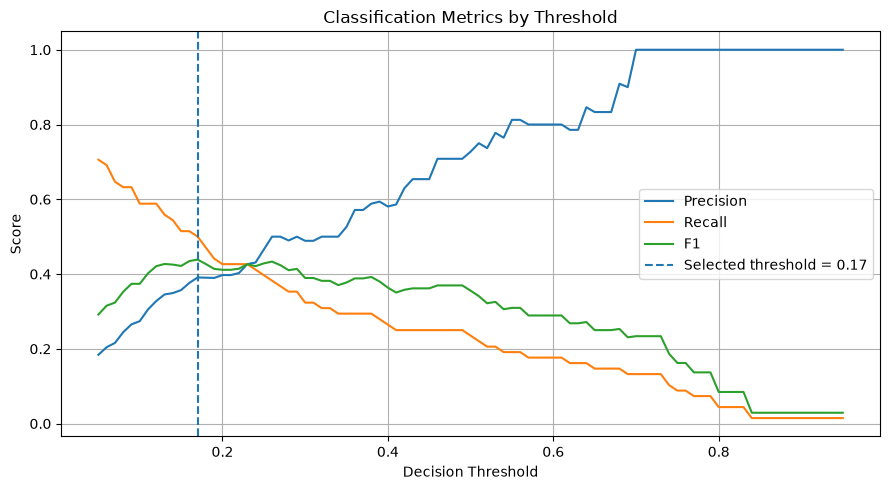

In [8]:

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    label="F1"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Selected threshold = {best_threshold:.2f}"
)

plt.title("Classification Metrics by Threshold")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Selected model: Baseline
Selected threshold: 0.17

Test classification report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1932
           1       0.46      0.57      0.51        68

    accuracy                           0.96      2000
   macro avg       0.72      0.78      0.75      2000
weighted avg       0.97      0.96      0.96      2000



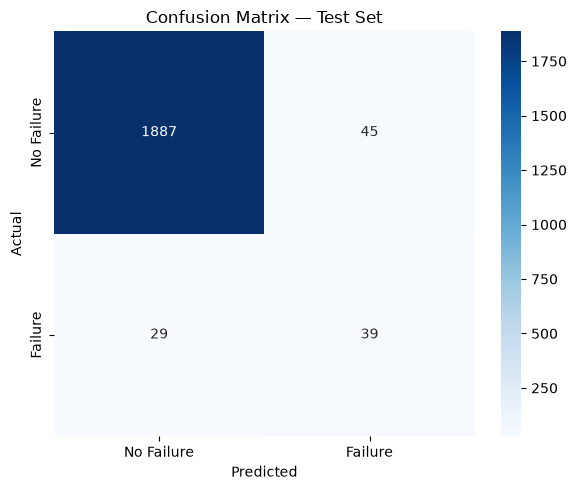

In [9]:

test_probabilities = best_model.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("Selected model:", best_name)
print("Selected threshold:", round(best_threshold, 2))

print("\nTest classification report:")
print(
    classification_report(
        y_test,
        test_predictions,
        zero_division=0
    )
)

cm = confusion_matrix(y_test, test_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.title("Confusion Matrix — Test Set")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()


## Results and Discussion

### Class Imbalance

The AI4I 2020 dataset contains 9,661 non-failure records and 339 failure records. The class distribution is approximately 28.5:1, indicating substantial class imbalance.

### Classification Strategies

Three approaches were evaluated: baseline logistic regression, class-weighted logistic regression, and random oversampling.

All models used the same training, validation, and testing splits. Oversampling was applied only to training observations to prevent data leakage.

### Model Comparison

The models were compared using precision, recall, F1-score, and Average Precision on the validation set.

The preferred model was selected based on validation Average Precision. Its decision threshold was subsequently optimized using validation F1-score.

The selected model and threshold should be reported together with their actual validation results.

### Test Evaluation

The final model was evaluated on the previously unused test set.

The confusion matrix and classification report were used to examine correct predictions, false alarms, and missed machine failures.

### Conclusion

The experiment demonstrates why accuracy alone is insufficient for imbalanced classification.

Class weighting and oversampling provide alternative strategies for improving minority-class detection. Their effectiveness must be evaluated empirically rather than assumed.

Threshold selection is also important because it changes the trade-off between precision and recall.

In practical predictive maintenance applications, missed failures and false alarms may have different operational costs. These costs should be considered when choosing a deployment threshold.

### Final Model Selection

Selected model: [insert model name]

Selected threshold: [insert threshold]

Validation F1-score: [insert value]

Reason for selection: The model achieved the highest validation Average Precision among the evaluated approaches. The decision threshold was selected to maximize validation F1-score.